In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
print(os.listdir('/content/drive/MyDrive/amdsd_light'))

Mounted at /content/drive
['amdsd_light']


In [ ]:
import torch
print("GPU disponible :", torch.cuda.is_available())
print("Device :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU disponible : True
Device : Tesla T4


Text Split details

In [ ]:
import os
import numpy as np
from PIL import Image

BASE = "/content/drive/MyDrive/amdsd_light/amdsd_light"

print("=== TEST SPLIT DETAILS ===")
for bio in ["PED", "SRF"]:
    mask_dir = os.path.join(BASE, "masques_binaires", "test_split", bio)
    files = [f for f in os.listdir(mask_dir) if "_AMDSD" in f]
    non_vides = sum(1 for f in files if np.sum(np.array(Image.open(os.path.join(mask_dir, f)).convert("L")) > 127) > 0)
    print(f"{bio}: {non_vides} non-empty masks / {len(files)} total")

ped_dir = os.path.join(BASE, "masques_binaires", "test_split", "PED")
srf_dir = os.path.join(BASE, "masques_binaires", "test_split", "SRF")
ped_set = set(f for f in os.listdir(ped_dir) if "_AMDSD" in f and np.sum(np.array(Image.open(os.path.join(ped_dir, f)).convert("L")) > 127) > 0)
srf_set = set(f for f in os.listdir(srf_dir) if "_AMDSD" in f and np.sum(np.array(Image.open(os.path.join(srf_dir, f)).convert("L")) > 127) > 0)
print(f"Images with non-empty PED: {len(ped_set)}")
print(f"Images with non-empty SRF: {len(srf_set)}")
print(f"Images with PED AND SRF: {len(ped_set & srf_set)}")
print(f"Images with PED OR SRF: {len(ped_set | srf_set)}")

# TRAINING WITH DATA AUGMENTATION - AMD-SD (PED + SRF)


In [ ]:
# ============================================================
# TRAINING WITH DATA AUGMENTATION - AMD-SD (PED + SRF)
# ============================================================
!pip install -q transformers

import os, random
import torch, torch.nn as nn
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel
import torchvision.transforms.functional as TF

# --- 1. Auto-detect data folder ---
CANDIDATES = [
    "/content/drive/MyDrive/amdsd_light/amdsd_light",
    "/content/drive/MyDrive/amdsd_light",
]
BASE = None
for c in CANDIDATES:
    if os.path.exists(os.path.join(c, "train_split", "images")):
        BASE = c
        break

if BASE is None:
    print("Data folder not found.")
    raise SystemExit

print(f"Data folder: {BASE}")

# --- 2. Dataset with data augmentation ---
class OCTDataset(Dataset):
    def __init__(self, split, biomarker, augment=False):
        self.img_dir = os.path.join(BASE, split, "images")
        self.mask_dir = os.path.join(BASE, "masques_binaires", split, biomarker)
        self.files = [f for f in os.listdir(self.img_dir) if "_AMDSD" in f]
        self.augment = augment
        print(f"{split}/{biomarker}: {len(self.files)} images (augment={augment})")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        f = self.files[idx]
        img = Image.open(os.path.join(self.img_dir, f)).convert("RGB").resize((224, 224))
        mask_path = os.path.join(self.mask_dir, f)
        if os.path.exists(mask_path):
            mask = Image.open(mask_path).convert("L").resize((224, 224), Image.NEAREST)
        else:
            mask = Image.new("L", (224, 224), 0)

        # Data augmentation (train only)
        if self.augment:
            if random.random() > 0.5:
                img = TF.hflip(img); mask = TF.hflip(mask)
            if random.random() > 0.5:
                angle = random.uniform(-15, 15)
                img = TF.rotate(img, angle); mask = TF.rotate(mask, angle)
            if random.random() > 0.5:
                img = TF.adjust_brightness(img, random.uniform(0.8, 1.2))
                img = TF.adjust_contrast(img, random.uniform(0.8, 1.2))

        img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        mask = (torch.from_numpy(np.array(mask)).float() / 255.0 > 0.5).float()
        return img, mask

# --- 3. Model ---
class DINOv2Seg(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = AutoModel.from_pretrained("facebook/dinov2-base")
        for p in self.backbone.parameters():
            p.requires_grad = True
        hidden = self.backbone.config.hidden_size
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, 256, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(256, 128, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 1, 1),
        )

    def forward(self, x):
        out = self.backbone(x).last_hidden_state
        tokens = out[:, 1:, :]
        B, N, C = tokens.shape
        h = w = int(N ** 0.5)
        feat = tokens.reshape(B, h, w, C).permute(0, 3, 1, 2)
        mask = self.decoder(feat)
        return nn.functional.interpolate(mask, size=x.shape[-2:], mode="bilinear", align_corners=False)

# --- 4. Dice per image ---
def dice_per_image(pred_logits, target, eps=1e-6):
    pred = (torch.sigmoid(pred_logits) > 0.5).float()
    target = (target > 0.5).float()
    dices = []
    for i in range(pred.shape[0]):
        p = pred[i].view(-1)
        t = target[i].view(-1)
        inter = (p * t).sum()
        d = (2 * inter + eps) / (p.sum() + t.sum() + eps)
        dices.append(d.item())
    return dices

# --- 5. Training loop ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

EPOCHS = 20
BATCH = 4
LR = 1e-5
POS_WEIGHT = {"PED": 5.0, "SRF": 10.0}

for bio in ["PED", "SRF"]:
    print(f"\n{'='*60}\n=== TRAINING {bio} (with augmentation) ===\n{'='*60}")
    train_ds = OCTDataset("train_split", bio, augment=True)
    val_ds = OCTDataset("val_split", bio, augment=False)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=BATCH, num_workers=2)

    model = DINOv2Seg().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=3)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT[bio]]).to(DEVICE))

    best_dice = 0
    best_epoch = 0

    for epoch in range(EPOCHS):
        # --- Train ---
        model.train()
        total_loss = 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE).unsqueeze(1)
            opt.zero_grad()
            loss = crit(model(imgs), masks)
            loss.backward()
            opt.step()
            total_loss += loss.item()

        # --- Validation ---
        model.eval()
        all_dices = []
        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE).unsqueeze(1)
                preds = model(imgs)
                all_dices.extend(dice_per_image(preds, masks))

        val_dice = np.mean(all_dices)
        scheduler.step(val_dice)

        if val_dice > best_dice:
            best_dice = val_dice
            best_epoch = epoch + 1
            torch.save(model.state_dict(), f"/content/drive/MyDrive/dinov2_{bio}_aug_best.pt")
            print(f"Epoch {epoch+1}/{EPOCHS} | Loss={total_loss/len(train_loader):.4f} | Val Dice={val_dice:.4f} ⭐ (best)")
        else:
            print(f"Epoch {epoch+1}/{EPOCHS} | Loss={total_loss/len(train_loader):.4f} | Val Dice={val_dice:.4f}")

    print(f"\n✅ Best {bio} (aug): Dice={best_dice:.4f} at epoch {best_epoch}/{EPOCHS}")
    print(f"Model saved: dinov2_{bio}_aug_best.pt")

print("\n🎉 Training with augmentation complete!")

Data folder: /content/drive/MyDrive/amdsd_light/amdsd_light
Device: cuda

=== TRAINING PED (with augmentation) ===
train_split/PED: 1406 images (augment=True)
val_split/PED: 43 images (augment=False)


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Epoch 1/20 | Loss=0.0740 | Val Dice=0.6525 ⭐ (best)
Epoch 2/20 | Loss=0.0319 | Val Dice=0.6570 ⭐ (best)
Epoch 3/20 | Loss=0.0250 | Val Dice=0.7232 ⭐ (best)
Epoch 4/20 | Loss=0.0236 | Val Dice=0.6875
Epoch 5/20 | Loss=0.0226 | Val Dice=0.6841
Epoch 6/20 | Loss=0.0234 | Val Dice=0.7405 ⭐ (best)
Epoch 7/20 | Loss=0.0193 | Val Dice=0.7171
Epoch 8/20 | Loss=0.0208 | Val Dice=0.7205
Epoch 9/20 | Loss=0.0187 | Val Dice=0.7063
Epoch 10/20 | Loss=0.0183 | Val Dice=0.6966
Epoch 11/20 | Loss=0.0161 | Val Dice=0.7143
Epoch 12/20 | Loss=0.0160 | Val Dice=0.6870
Epoch 13/20 | Loss=0.0152 | Val Dice=0.7045
Epoch 14/20 | Loss=0.0160 | Val Dice=0.6839
Epoch 15/20 | Loss=0.0139 | Val Dice=0.6858
Epoch 16/20 | Loss=0.0136 | Val Dice=0.7168
Epoch 17/20 | Loss=0.0141 | Val Dice=0.7003
Epoch 18/20 | Loss=0.0136 | Val Dice=0.7252
Epoch 19/20 | Loss=0.0124 | Val Dice=0.7136
Epoch 20/20 | Loss=0.0123 | Val Dice=0.7085

✅ Best PED (aug): Dice=0.7405 at epoch 6/20
Model saved: dinov2_PED_aug_best.pt

=== TRAININ

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Epoch 1/20 | Loss=0.0511 | Val Dice=0.5814 ⭐ (best)
Epoch 2/20 | Loss=0.0128 | Val Dice=0.6282 ⭐ (best)
Epoch 3/20 | Loss=0.0114 | Val Dice=0.6351 ⭐ (best)
Epoch 4/20 | Loss=0.0093 | Val Dice=0.6790 ⭐ (best)
Epoch 5/20 | Loss=0.0094 | Val Dice=0.7000 ⭐ (best)
Epoch 6/20 | Loss=0.0084 | Val Dice=0.6722
Epoch 7/20 | Loss=0.0081 | Val Dice=0.7317 ⭐ (best)
Epoch 8/20 | Loss=0.0066 | Val Dice=0.7142
Epoch 9/20 | Loss=0.0061 | Val Dice=0.7459 ⭐ (best)
Epoch 10/20 | Loss=0.0074 | Val Dice=0.7003
Epoch 11/20 | Loss=0.0062 | Val Dice=0.7231
Epoch 12/20 | Loss=0.0057 | Val Dice=0.6370
Epoch 13/20 | Loss=0.0058 | Val Dice=0.7310
Epoch 14/20 | Loss=0.0053 | Val Dice=0.7046
Epoch 15/20 | Loss=0.0045 | Val Dice=0.6785
Epoch 16/20 | Loss=0.0045 | Val Dice=0.6936
Epoch 17/20 | Loss=0.0046 | Val Dice=0.6647
Epoch 18/20 | Loss=0.0040 | Val Dice=0.7293
Epoch 19/20 | Loss=0.0036 | Val Dice=0.6830
Epoch 20/20 | Loss=0.0036 | Val Dice=0.6714

✅ Best SRF (aug): Dice=0.7459 at epoch 9/20
Model saved: dinov2_S

Test Evaluation — AMD-SD (PED + SRF)

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel

BASE = "/content/drive/MyDrive/amdsd_light/amdsd_light"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

class OCTDataset(Dataset):
    def __init__(self, split, biomarker):
        self.img_dir = os.path.join(BASE, split, "images")
        self.mask_dir = os.path.join(BASE, "masques_binaires", split, biomarker)
        self.files = [f for f in os.listdir(self.img_dir) if "_AMDSD" in f]
        print(f"{split}/{biomarker}: {len(self.files)} images")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        f = self.files[idx]
        img = Image.open(os.path.join(self.img_dir, f)).convert("RGB").resize((224, 224))
        mask_path = os.path.join(self.mask_dir, f)
        mask = Image.open(mask_path).convert("L").resize((224, 224), Image.NEAREST) if os.path.exists(mask_path) else Image.new("L", (224, 224), 0)
        img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        mask = (torch.from_numpy(np.array(mask)).float() / 255.0 > 0.5).float()
        return img, mask

class DINOv2Seg(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = AutoModel.from_pretrained("facebook/dinov2-base")
        hidden = self.backbone.config.hidden_size
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, 256, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(256, 128, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 1, 1),
        )
    def forward(self, x):
        out = self.backbone(x).last_hidden_state
        tokens = out[:, 1:, :]
        B, N, C = tokens.shape
        h = w = int(N ** 0.5)
        feat = tokens.reshape(B, h, w, C).permute(0, 3, 1, 2)
        return nn.functional.interpolate(self.decoder(feat), size=x.shape[-2:], mode="bilinear", align_corners=False)

def per_image_metrics(pred_logits, target, eps=1e-6):
    pred = (torch.sigmoid(pred_logits) > 0.5).float()
    target = (target > 0.5).float()
    res = []
    for i in range(pred.shape[0]):
        p = pred[i].view(-1); t = target[i].view(-1)
        tp = (p * t).sum(); fp = (p * (1 - t)).sum(); fn = ((1 - p) * t).sum()
        dice = (2*tp + eps) / (p.sum() + t.sum() + eps)
        iou = (tp + eps) / (tp + fp + fn + eps)
        prec = (tp + eps) / (tp + fp + eps)
        rec = (tp + eps) / (tp + fn + eps)
        res.append((dice.item(), iou.item(), prec.item(), rec.item()))
    return res

for bio in ["PED", "SRF"]:
    print(f"\n{'='*50}\n=== TEST {bio} (aug model) ===\n{'='*50}")
    test_ds = OCTDataset("test_split", bio)
    test_loader = DataLoader(test_ds, batch_size=4, num_workers=2)

    model = DINOv2Seg().to(DEVICE)
    model.load_state_dict(torch.load(f"/content/drive/MyDrive/dinov2_{bio}_aug_best.pt", map_location=DEVICE))
    model.eval()

    all_dice, all_iou, all_prec, all_rec = [], [], [], []
    with torch.no_grad():
        for imgs, masks in test_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE).unsqueeze(1)
            preds = model(imgs)
            for d, i, p, r in per_image_metrics(preds, masks):
                all_dice.append(d); all_iou.append(i); all_prec.append(p); all_rec.append(r)

    print(f"Images evaluated: {len(all_dice)}")
    print(f"Dice     : {np.mean(all_dice):.4f} (±{np.std(all_dice):.4f})")
    print(f"IoU      : {np.mean(all_iou):.4f} (±{np.std(all_iou):.4f})")
    print(f"Precision: {np.mean(all_prec):.4f} (±{np.std(all_prec):.4f})")
    print(f"Recall   : {np.mean(all_rec):.4f} (±{np.std(all_rec):.4f})")

Device: cuda

=== TEST PED (aug model) ===
test_split/PED: 119 images


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Images evaluated: 119
Dice     : 0.7050 (±0.2972)
IoU      : 0.6165 (±0.3218)
Precision: 0.7951 (±0.2220)
Recall   : 0.7445 (±0.3086)

=== TEST SRF (aug model) ===
test_split/SRF: 119 images


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Images evaluated: 119
Dice     : 0.8253 (±0.3183)
IoU      : 0.7955 (±0.3477)
Precision: 0.9089 (±0.1998)
Recall   : 0.8459 (±0.3066)


## Visual Results — Ground Truth vs Prediction (Test Set)

**Goal:** Generate qualitative examples to visually assess model performance on the test set.

**What this cell does:**
- Loads the augmented models (`dinov2_PED_aug_best.pt`, `dinov2_SRF_aug_best.pt`)
- Selects 3 test images with **non-empty masks** for each biomarker (PED and SRF)
- Runs inference on each image
- Displays a 4-column comparison:
  1. **OCT Image** — original input
  2. **Ground Truth** — expert annotation (binary mask)
  3. **Prediction** — model output (threshold = 0.5)
  4. **Overlay** — error visualization:
     - 🟢 **Green** = True Positive (correct detection)
     - 🔴 **Red** = False Positive (false alarm)
     - 🔵 **Blue** = False Negative (missed lesion)

**Outputs:**
- `visuel_PED_test_aug.png` saved on Drive
- `visuel_SRF_test_aug.png` saved on Drive

**Interpretation:**
- Mostly green → good segmentation
- Large red areas → model over-predicts (false alarms)
- Large blue areas → model misses lesions


Device: cuda

=== Generating visuals for PED ===


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Using 3 images: ['0739_12_AMDSD.png', '0740_12_AMDSD.png', '0741_12_AMDSD.png']


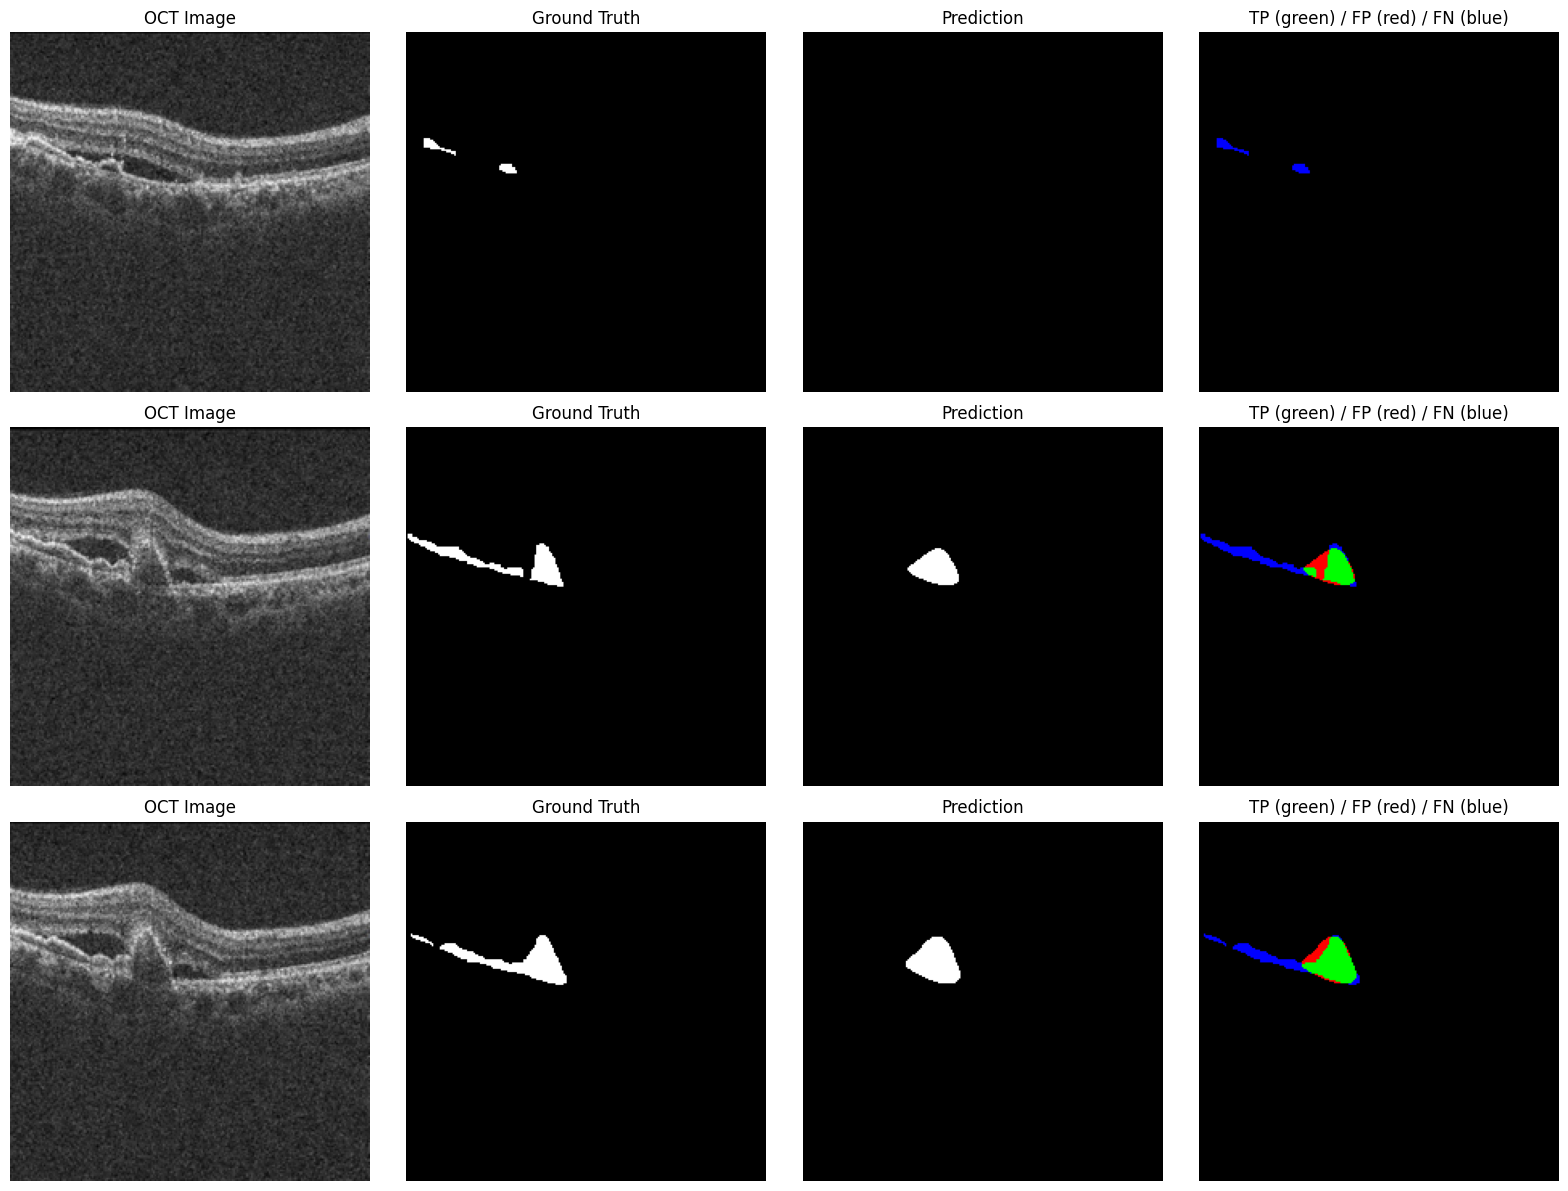

✅ Saved: /content/drive/MyDrive/visuel_PED_test_aug.png

=== Generating visuals for SRF ===


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Using 3 images: ['0992_139_AMDSD.png', '0993_139_AMDSD.png', '0994_139_AMDSD.png']


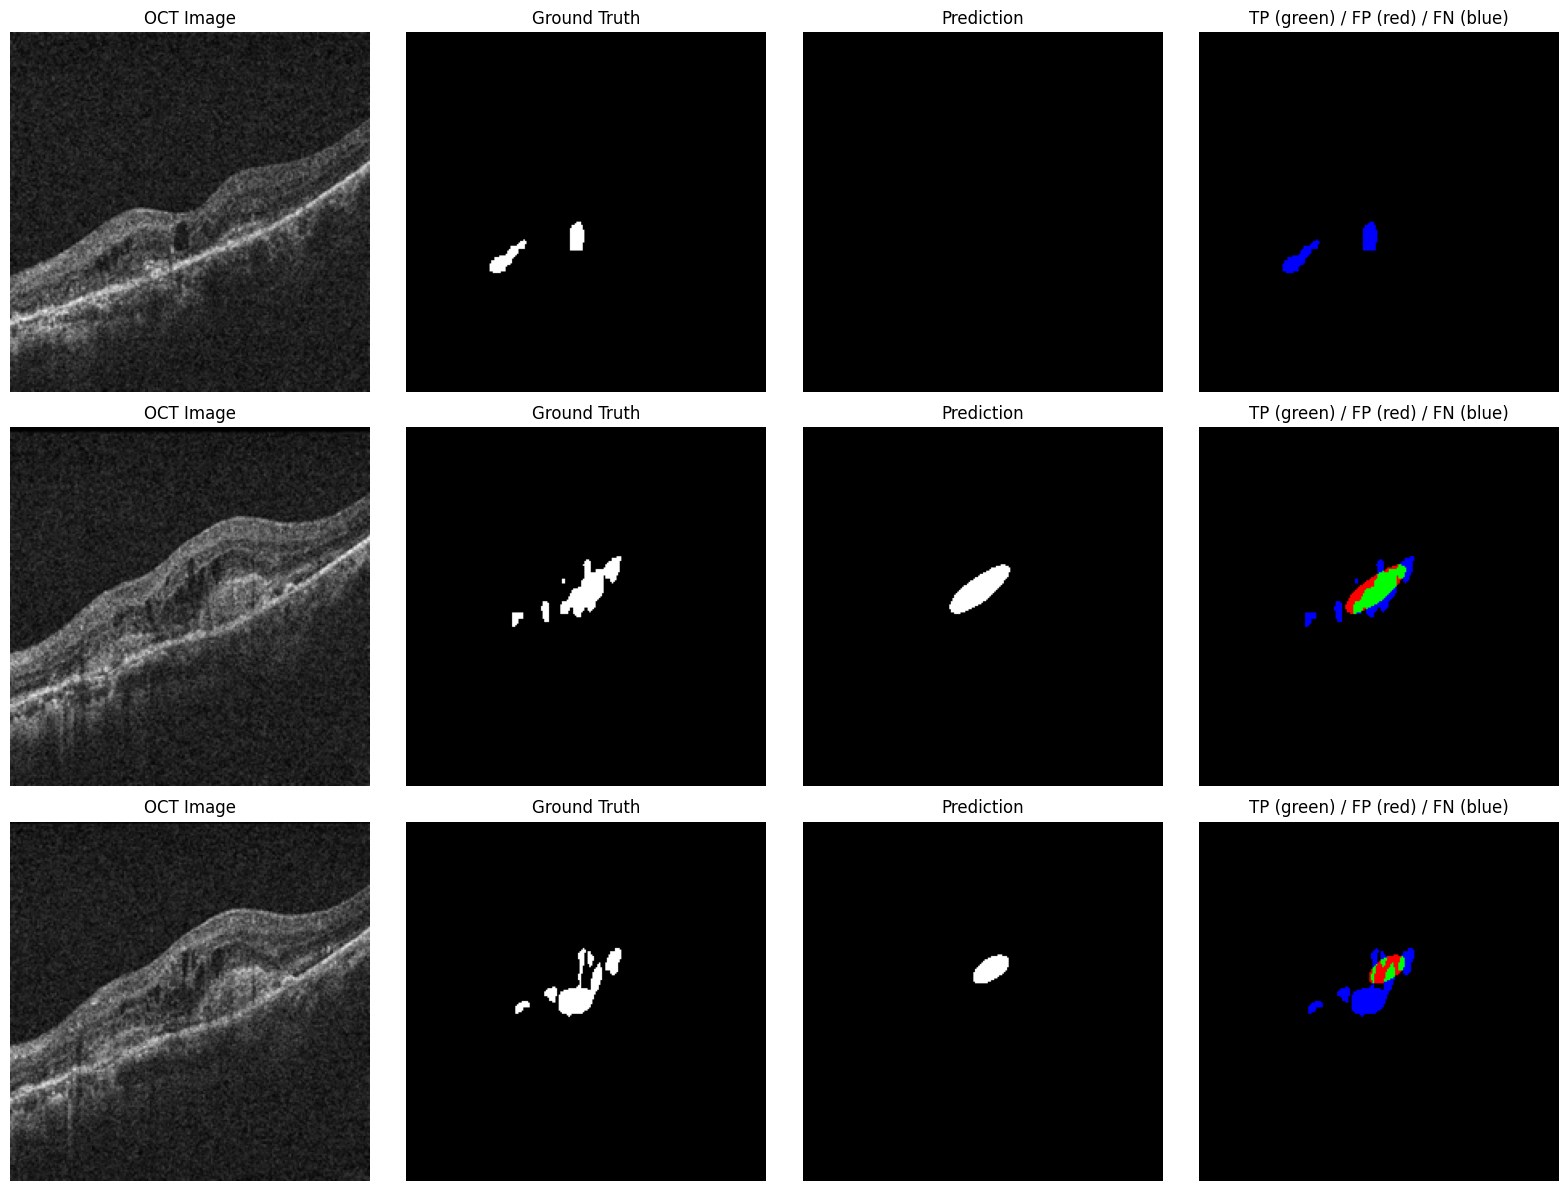

✅ Saved: /content/drive/MyDrive/visuel_SRF_test_aug.png


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoModel

BASE = "/content/drive/MyDrive/amdsd_light/amdsd_light"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

class DINOv2Seg(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = AutoModel.from_pretrained("facebook/dinov2-base")
        hidden = self.backbone.config.hidden_size
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, 256, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(256, 128, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 1, 1),
        )
    def forward(self, x):
        out = self.backbone(x).last_hidden_state
        tokens = out[:, 1:, :]
        B, N, C = tokens.shape
        h = w = int(N ** 0.5)
        feat = tokens.reshape(B, h, w, C).permute(0, 3, 1, 2)
        return nn.functional.interpolate(self.decoder(feat), size=x.shape[-2:], mode="bilinear", align_corners=False)

for bio in ["PED", "SRF"]:
    print(f"\n=== Generating visuals for {bio} ===")
    model = DINOv2Seg().to(DEVICE)
    model.load_state_dict(torch.load(f"/content/drive/MyDrive/dinov2_{bio}_aug_best.pt", map_location=DEVICE))
    model.eval()

    img_dir = os.path.join(BASE, "test_split", "images")
    mask_dir = os.path.join(BASE, "masques_binaires", "test_split", bio)

    # Take 3 images with non-empty masks
    files = []
    for f in os.listdir(img_dir):
        if "_AMDSD" in f and os.path.exists(os.path.join(mask_dir, f)):
            mask = np.array(Image.open(os.path.join(mask_dir, f)).convert("L"))
            if np.sum(mask > 127) > 0:
                files.append(f)
    files = files[:3]
    print(f"Using {len(files)} images: {files}")

    fig, axes = plt.subplots(len(files), 4, figsize=(16, 4*len(files)))
    if len(files) == 1:
        axes = axes.reshape(1, -1)

    for i, f in enumerate(files):
        img = Image.open(os.path.join(img_dir, f)).convert("RGB").resize((224, 224))
        mask = Image.open(os.path.join(mask_dir, f)).convert("L").resize((224, 224), Image.NEAREST)

        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float().unsqueeze(0) / 255.0
        with torch.no_grad():
            prob = torch.sigmoid(model(x.to(DEVICE))).cpu().squeeze().numpy()
        pred = (prob > 0.5).astype(np.uint8)

        gt = (np.array(mask) > 127).astype(np.uint8)
        # Overlay: TP green, FP red, FN blue
        overlay = np.zeros((*gt.shape, 3), dtype=np.uint8)
        overlay[(gt == 1) & (pred == 1)] = [0, 255, 0]    # TP: green
        overlay[(gt == 0) & (pred == 1)] = [255, 0, 0]    # FP: red
        overlay[(gt == 1) & (pred == 0)] = [0, 0, 255]    # FN: blue

        axes[i, 0].imshow(img); axes[i, 0].set_title("OCT Image"); axes[i, 0].axis("off")
        axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("Ground Truth"); axes[i, 1].axis("off")
        axes[i, 2].imshow(pred, cmap="gray"); axes[i, 2].set_title("Prediction"); axes[i, 2].axis("off")
        axes[i, 3].imshow(overlay); axes[i, 3].set_title("TP (green) / FP (red) / FN (blue)"); axes[i, 3].axis("off")

    plt.tight_layout()
    out_path = f"/content/drive/MyDrive/visuel_{bio}_test_aug.png"
    plt.savefig(out_path, dpi=150)
    plt.show()
    print(f"✅ Saved: {out_path}")

## Fairness analysis — Dice by sex and age group


In [ ]:
import os, re, numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from transformers import AutoModel

BASE = "/content/drive/MyDrive/amdsd_light/amdsd_light"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --- Model definition ---
class DINOv2Seg(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = AutoModel.from_pretrained("facebook/dinov2-base")
        hidden = self.backbone.config.hidden_size
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, 256, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(256, 128, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 1, 1),
        )

    def forward(self, x):
        out = self.backbone(x).last_hidden_state
        tokens = out[:, 1:, :]
        B, N, C = tokens.shape
        h = w = int(N ** 0.5)
        feat = tokens.reshape(B, h, w, C).permute(0, 3, 1, 2)
        return nn.functional.interpolate(self.decoder(feat), size=x.shape[-2:],
                                          mode="bilinear", align_corners=False)

# --- Reload demographics ---
DEMO_PATH = os.path.join(BASE, "Demographics of the participants.csv")
demo = pd.read_excel(DEMO_PATH)
demo.columns = [c.strip() for c in demo.columns]

def extract_eye_id(f):
    m = re.match(r"\d+_(\d+)_AMDSD", f)
    return int(m.group(1)) if m else None

# --- Per-biomarker analysis ---
def analyze(bio, model):
    img_dir = os.path.join(BASE, "test_split", "images")
    mask_dir = os.path.join(BASE, "masques_binaires", "test_split", bio)
    files = [f for f in os.listdir(img_dir) if "_AMDSD" in f]
    rows = []
    model.eval()
    with torch.no_grad():
        for f in files:
            img = Image.open(os.path.join(img_dir, f)).convert("RGB").resize((224, 224))
            mp = os.path.join(mask_dir, f)
            mask = Image.open(mp).convert("L").resize((224, 224), Image.NEAREST) if os.path.exists(mp) else Image.new("L", (224, 224), 0)
            x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE) / 255.
            m = (torch.from_numpy(np.array(mask)).float().unsqueeze(0).unsqueeze(0).to(DEVICE) / 255. > 0.5).float()
            pred = (torch.sigmoid(model(x)) > 0.5).float()
            tp = (pred * m).sum().item()
            denom = pred.sum().item() + m.sum().item()
            dice = (2 * tp + 1e-6) / (denom + 1e-6)
            rows.append({"file": f, "eye_id": extract_eye_id(f), "dice": dice})

    df = pd.DataFrame(rows).merge(demo, left_on="eye_id", right_on="Eye ID", how="inner")
    per_eye = df.groupby(["Eye ID", "Patient ID", "Sex", "Age(years)"])["dice"].mean().reset_index()
    per_eye["age_bin"] = pd.cut(per_eye["Age(years)"], bins=[49, 59, 69, 79, 100],
                                labels=["50-59", "60-69", "70-79", "80+"])

    print(f"\n{'='*55}\n=== {bio} — test_split ===")
    print(f"Images: {len(df)} | Eyes: {per_eye.shape[0]} | Patients: {per_eye['Patient ID'].nunique()}")
    print(f"Global Dice: {per_eye['dice'].mean():.4f}")
    print("\nBy sex:")
    print(per_eye.groupby("Sex")["dice"].agg(["mean", "std", "count"]).round(4))
    print("\nBy age group:")
    print(per_eye.groupby("age_bin", observed=True)["dice"].agg(["mean", "std", "count"]).round(4))

    by_sex = per_eye.groupby("Sex")["dice"].mean()
    if {"Female", "Male"}.issubset(by_sex.index):
        print(f"\nDice gap (Female - Male) = {by_sex['Female'] - by_sex['Male']:+.4f}")
    return per_eye

# --- Load models and run analysis ---
model_ped = DINOv2Seg().to(DEVICE)
model_ped.load_state_dict(torch.load("/content/drive/MyDrive/dinov2_PED_aug_best.pt", map_location=DEVICE))

model_srf = DINOv2Seg().to(DEVICE)
model_srf.load_state_dict(torch.load("/content/drive/MyDrive/dinov2_SRF_aug_best.pt", map_location=DEVICE))

per_eye_ped = analyze("PED", model_ped)
per_eye_srf = analyze("SRF", model_srf)

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


=== PED — test_split ===
Images: 119 | Eyes: 7 | Patients: 7
Global Dice: 0.6986

By sex:
          mean     std  count
Sex                          
Female  0.6411  0.3055      2
Male    0.7216  0.1073      5

By age group:
           mean     std  count
age_bin                       
50-59    0.8571     NaN      1
60-69    0.7670  0.1199      3
70-79    0.5774  0.1353      3

Dice gap (Female - Male) = -0.0805

=== SRF — test_split ===
Images: 119 | Eyes: 7 | Patients: 7
Global Dice: 0.8068

By sex:
          mean     std  count
Sex                          
Female  0.7654  0.3318      2
Male    0.8234  0.2273      5

By age group:
           mean     std  count
age_bin                       
50-59    1.0000     NaN      1
60-69    0.7843  0.3124      3
70-79    0.7649  0.2029      3

Dice gap (Female - Male) = -0.0580


## Visualizing subgroup disparities — Dice by sex and age group

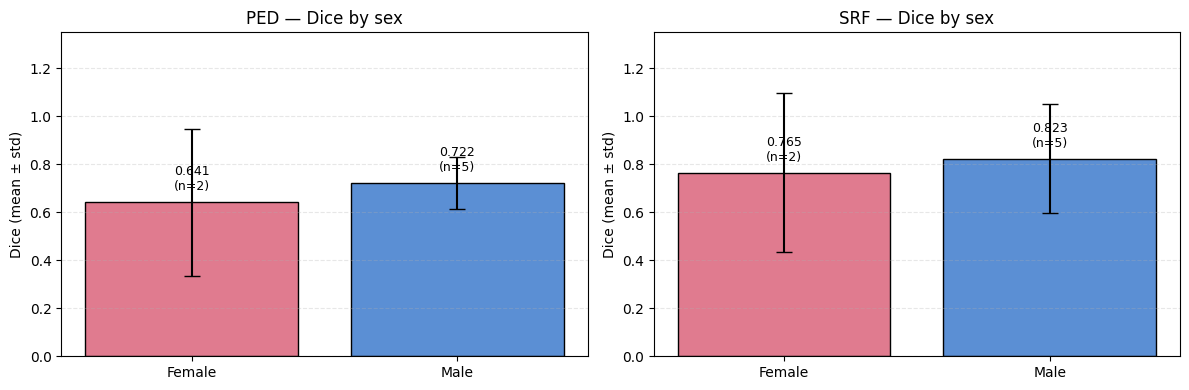

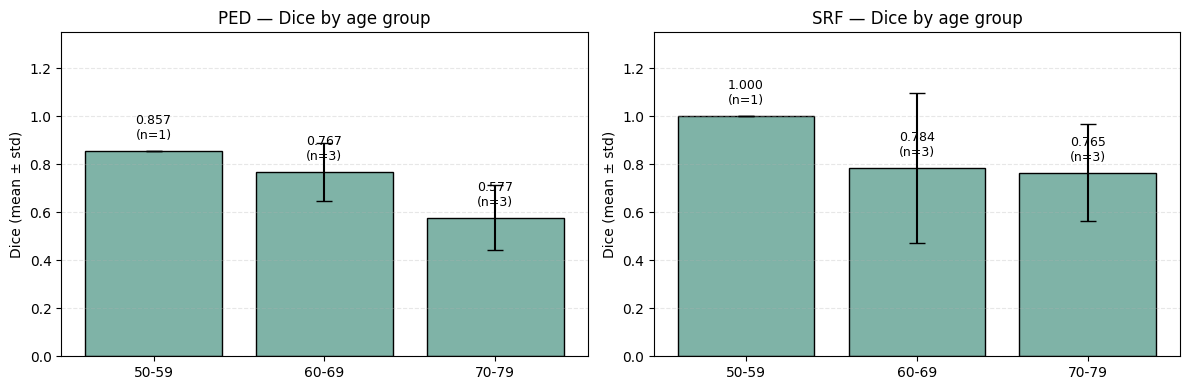

✓ Saved: dice_by_sex.png, dice_by_age.png


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# --- Values already computed on GPU (from the test_split analysis) ---
# PED by sex
ped_sex = {"Female": (0.6411, 0.3055, 2), "Male": (0.7216, 0.1073, 5)}
# SRF by sex
srf_sex = {"Female": (0.7654, 0.3318, 2), "Male": (0.8234, 0.2273, 5)}
# PED by age
ped_age = {"50-59": (0.8571, 0.0, 1), "60-69": (0.7670, 0.1199, 3), "70-79": (0.5774, 0.1353, 3)}
# SRF by age
srf_age = {"50-59": (1.0000, 0.0, 1), "60-69": (0.7843, 0.3124, 3), "70-79": (0.7649, 0.2029, 3)}


def plot_bar(ax, data, title, colors, ylabel="Dice (mean ± std)"):
    labels = list(data.keys())
    means = [data[k][0] for k in labels]
    stds = [data[k][1] for k in labels]
    ns = [data[k][2] for k in labels]
    ax.bar(labels, means, yerr=stds, capsize=6, color=colors, edgecolor="black")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.35)
    for i, (m, n) in enumerate(zip(means, ns)):
        ax.text(i, m + 0.05, f"{m:.3f}\n(n={n})", ha="center", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.3)


# --- Figure 1: Dice by sex ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_bar(axes[0], ped_sex, "PED — Dice by sex", ["#e07b8f", "#5b8fd4"])
plot_bar(axes[1], srf_sex, "SRF — Dice by sex", ["#e07b8f", "#5b8fd4"])
plt.tight_layout()
plt.savefig("dice_by_sex.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Figure 2: Dice by age group ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_bar(axes[0], ped_age, "PED — Dice by age group", ["#7fb3a7"] * 3)
plot_bar(axes[1], srf_age, "SRF — Dice by age group", ["#7fb3a7"] * 3)
plt.tight_layout()
plt.savefig("dice_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

print("✓ Saved: dice_by_sex.png, dice_by_age.png")